# Embedding audit of reveal_v2

**Question.** Our judge is trained on generated tutor replies (`data/reveal_v2.jsonl`). Do those replies carry signals that
should not matter (which model wrote them, where the context came from) as strongly as the one that should (does the reply
reveal the answer)? And does a classifier trained on our data work on the human-labelled benchmark MRBench?

**How.** Embed every tutor reply with 4 embedding models (2 local, 2 Gemini), then fit a simple logistic-regression probe
on top. AUC 0.5 = no signal, 1.0 = perfect. Cross-validation is grouped by problem, so no problem is in both train and test.
Code: `embed_audit.py`. Raw numbers: `results/embed-audit/*.json`.

**TL;DR**
1. Which model wrote a reply is as easy to read as the label (AUC 0.91-0.97 vs 0.89-0.95). A judge trained on this data can learn "sounds like Claude" for free.
2. The label does transfer to MRBench (best 0.86, gemini-embedding-2), but clearly lower than on our own val split (0.94). Our val score is optimistic.
3. Our generated replies look different from MRBench replies: a probe tells them apart at 0.94-0.99.
4. v2 does not clearly beat v1 on transfer in embedding space.
5. Training on one writer and testing on another costs only 2-9 points, so style is a secondary issue. The main gap is ours vs MRBench (section 7).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import embed_audit as ea

OUT = Path("results/embed-audit")
MODELS = ["minilm", "bge-small", "gemini-embedding-001", "gemini-embedding-2"]
R = {m: json.load(open(OUT / f"{m}.json")) for m in MODELS}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#9D9D9D"]


def bars(ax, groups, series, title, ylim=(0.4, 1.0), chance=0.5):
    """Grouped bars: groups on the x axis, one bar per series. series = {name: [value per group]}."""
    w = 0.8 / len(series)
    x = np.arange(len(groups))
    for i, (name, vals) in enumerate(series.items()):
        b = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=name, color=COLORS[i % len(COLORS)])
        ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
    if chance is not None:
        ax.axhline(chance, color="k", lw=0.8, ls="--")
    ax.set_xticks(x, groups, fontsize=8)
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.legend(fontsize=7, loc="lower right")

## 1. All numbers

In [2]:
rows = {f"{sec}.{k}": {m: R[m][sec][k] for m in MODELS}
        for sec in ("probe_cv", "transfer", "silhouette", "domain", "pairs")
        for k in R[MODELS[0]][sec] if not k.endswith("_n")}
pd.DataFrame(rows).T.round(3)

,minilm,bge-small,gemini-embedding-001,gemini-embedding-2
probe_cv.label,0.887,0.892,0.947,0.948
probe_cv.generator,0.909,0.907,0.974,0.964
probe_cv.context_source,0.659,0.665,0.724,0.733
probe_cv.generator_in_yes,0.882,0.877,0.967,0.955
probe_cv.generator_in_no,0.927,0.936,0.980,0.974
transfer.v2_val,0.873,0.891,0.953,0.941
transfer.v1_val,0.987,0.986,0.997,0.998
transfer.v2_mrbench,0.705,0.772,0.783,0.859
transfer.v2_mrbench_Bridge,0.711,0.790,0.795,0.822
transfer.v2_mrbench_MathDial,0.830,0.841,0.918,0.896


## 2. Style is as readable as the label

`label` = reveal vs guide. `generator` = Claude vs Gemini wrote it. `in yes` / `in no` repeat the generator probe inside a
single label, so it cannot be the label leaking through. `context_source` = MathDial vs GSM8K context.

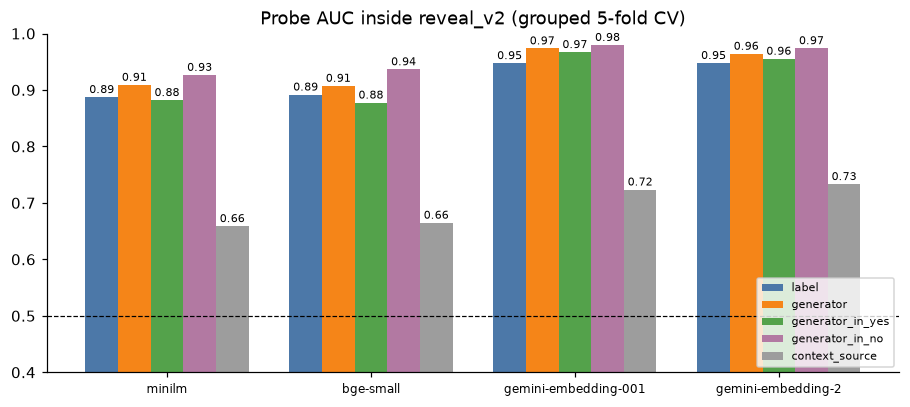

In [3]:
keys = ["label", "generator", "generator_in_yes", "generator_in_no", "context_source"]
fig, ax = plt.subplots(figsize=(10, 4))
bars(ax, MODELS, {k: [R[m]["probe_cv"][k] for m in MODELS] for k in keys}, "Probe AUC inside reveal_v2 (grouped 5-fold CV)")
plt.show()

**Reading.** For every model the generator bar is at or above the label bar, and it survives inside one label.
Context source is weaker but above chance. A classifier fitted on this data cannot tell "reveals" apart from "written by X"
unless we control for it.

## 3. Does it transfer to MRBench?

Probe fitted on the train split, scored on our val split and on MRBench (all, and by source). Same for v1 (`data/gsm8k.jsonl`).

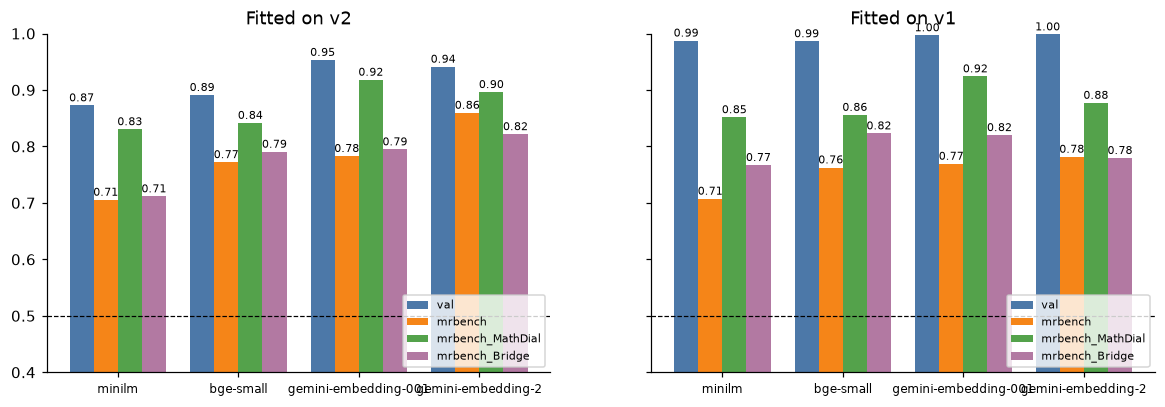

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, tag in zip(axs, ("v2", "v1")):
    ks = [f"{tag}_val", f"{tag}_mrbench", f"{tag}_mrbench_MathDial", f"{tag}_mrbench_Bridge"]
    bars(ax, MODELS, {k.replace(tag + "_", ""): [R[m]["transfer"][k] for m in MODELS] for k in ks}, f"Fitted on {tag}")
plt.show()

**Reading.** Inside our own data the probe looks great (v2 val 0.87-0.95, v1 val near 1.0, which is the v1 shortcut).
On MRBench it drops to 0.71-0.86. MathDial transfers better than Bridge, which makes sense since our contexts come from
MathDial and GSM8K. v2 vs v1 on MRBench is mixed: clearly better only for gemini-embedding-2.
The MRBench total can be below both slices because the two sources sit at different score levels; it is not their average.

## 4. Domain gap: our replies do not look like MRBench replies

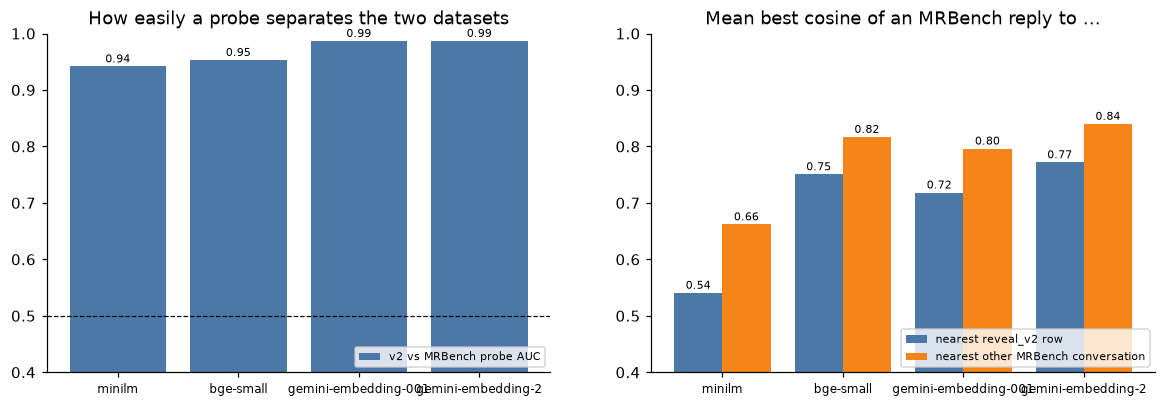

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
bars(axs[0], MODELS, {"v2 vs MRBench probe AUC": [R[m]["domain"]["probe_v2_vs_mrbench"] for m in MODELS]},
     "How easily a probe separates the two datasets")
bars(axs[1], MODELS, {"nearest reveal_v2 row": [R[m]["domain"]["nn_to_v2"] for m in MODELS],
                      "nearest other MRBench conversation": [R[m]["domain"]["nn_within_mrbench"] for m in MODELS]},
     "Mean best cosine of an MRBench reply to ...", ylim=(0.4, 1.0), chance=None)
plt.show()

**Reading.** 0.94-0.99 separability, and every MRBench reply is closer to other MRBench replies than to anything we
generated. Transfer numbers are therefore partly a measure of how much label signal both datasets happen to share.

## 5. Minimal pairs

Cosine between the guide and the reveal of the same context. Minimal pairs differ in a few words by design; free contexts
are two independently written replies; the floor pairs a guide with a random other reveal. Compare within a model only.

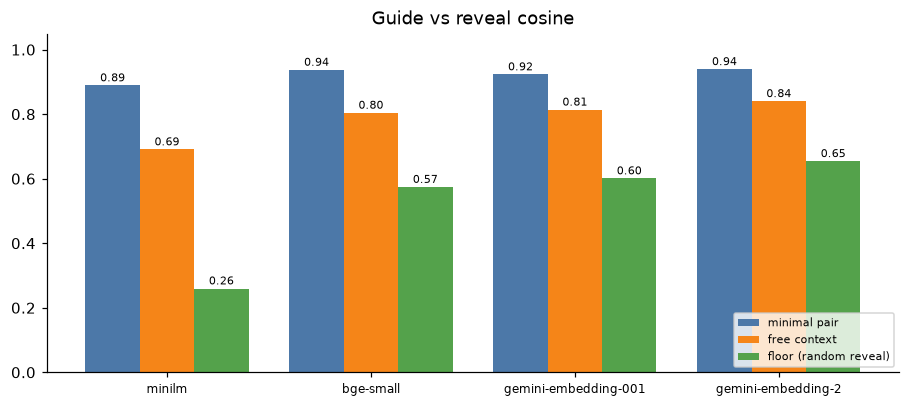

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
bars(ax, MODELS, {"minimal pair": [R[m]["pairs"]["pair"] for m in MODELS],
                  "free context": [R[m]["pairs"]["free"] for m in MODELS],
                  "floor (random reveal)": [R[m]["pairs"]["free_random"] for m in MODELS]},
     "Guide vs reveal cosine", ylim=(0.0, 1.05), chance=None)
plt.show()

## 6. 2D maps

PCA and t-SNE of 1,500 reveal_v2 rows plus 800 MRBench rows, coloured by generator, label and dataset. Silhouette is about
0.01 for everything, so do not expect clean blobs: the signals above are directions a linear probe finds, not clusters.

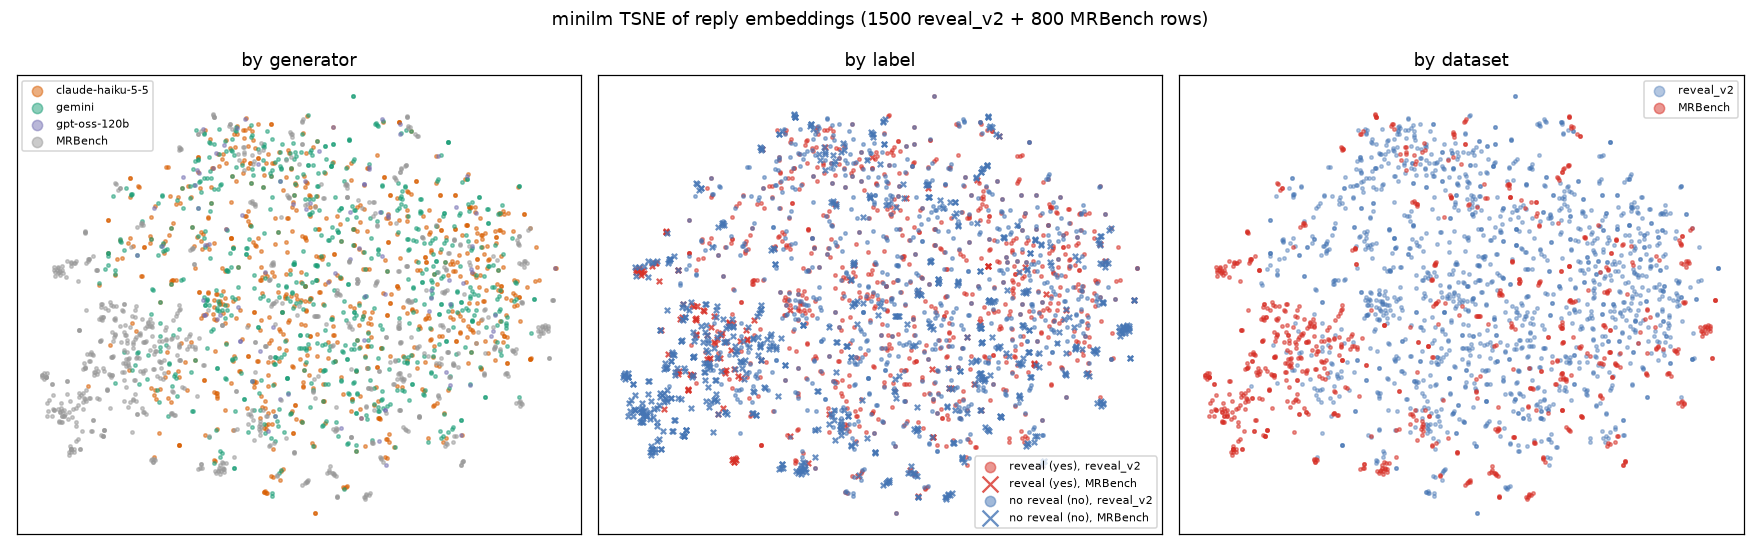

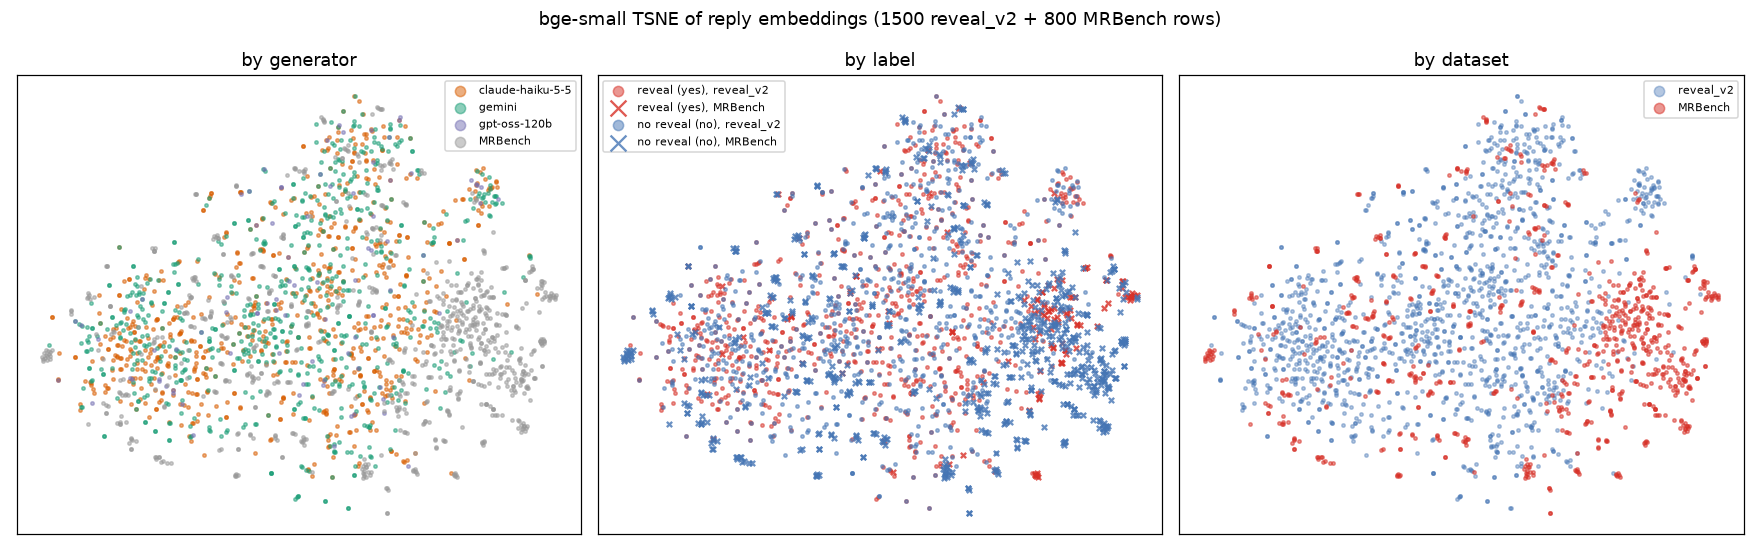

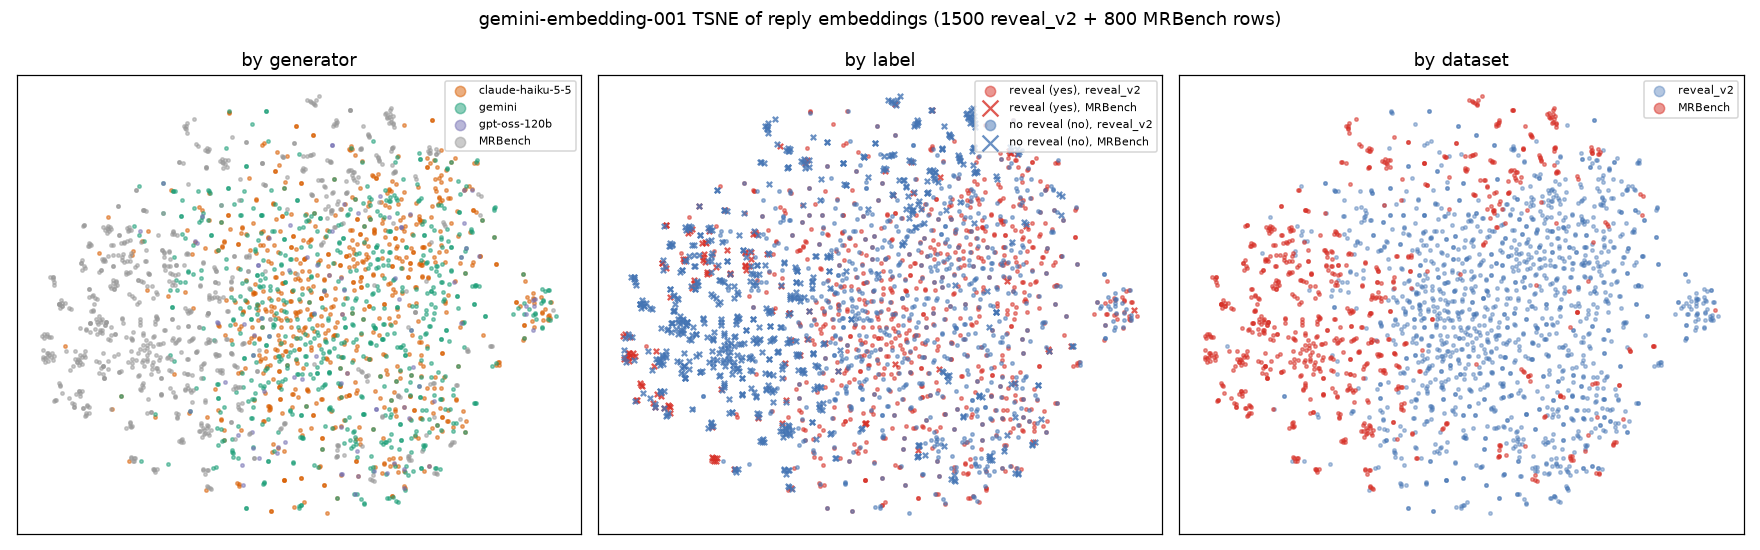

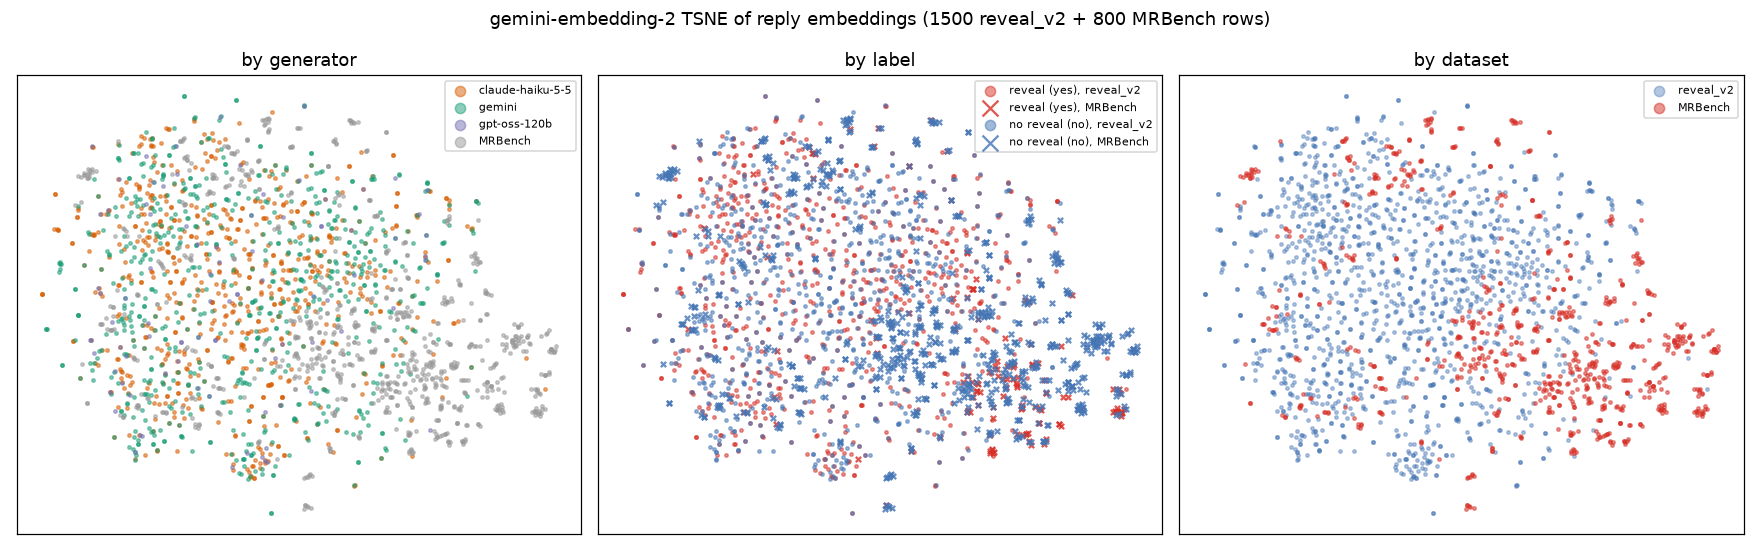

In [7]:
for m in MODELS:
    display(Image(OUT / f"{m}_tsne.png", width=1000))

### Why the maps show no clusters

PCA and t-SNE are unsupervised: they keep whatever varies most between replies, which is mostly the topic (the math
problem, the numbers, the length). Reveal vs guide and Claude vs Gemini are small, consistent shifts along one direction
out of 384-768. They add up to a strong signal for a linear probe but are invisible next to the topic variation, which is
also why silhouette is about 0.01. The one thing that does show up is the dataset split (MRBench grey/red on one side),
because that difference is big.

So no plot setting will make honest label clusters appear. What we can do is plot along the direction the probe found.
Below, each reply's out-of-fold probe score (it never saw that reply's problem in training): if the two colours sit apart,
the embedding separates them, even though the 2D maps above look mixed.

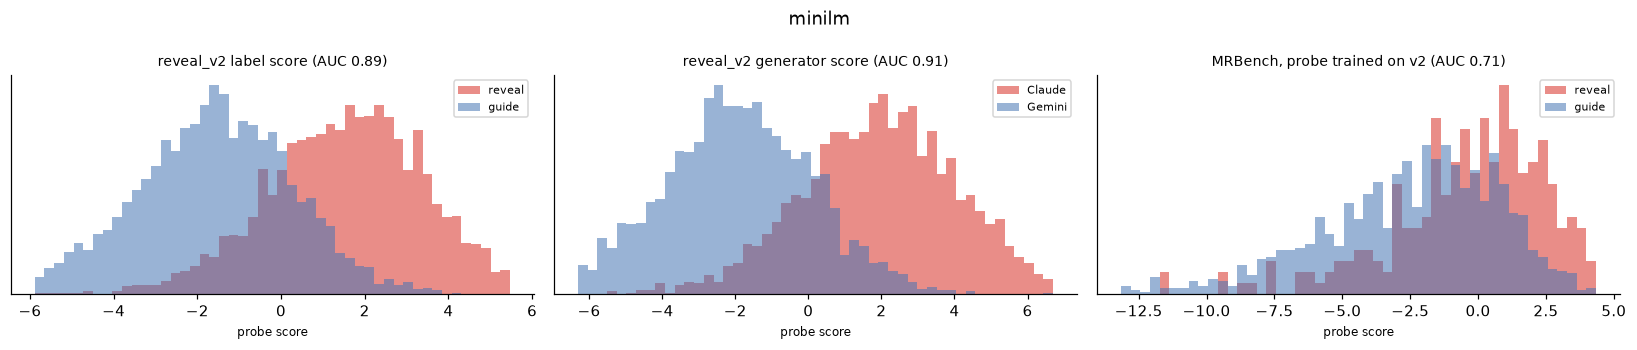

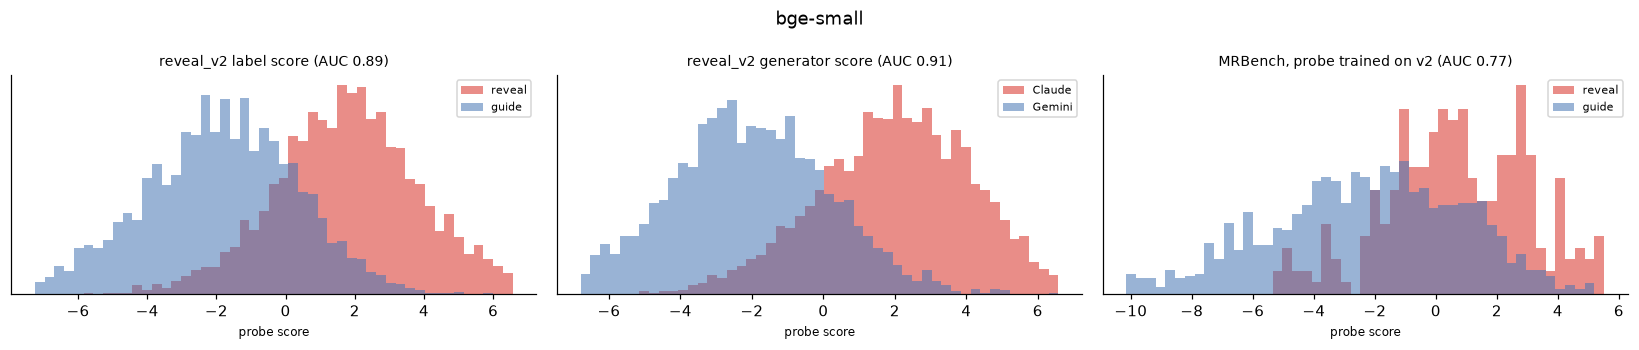

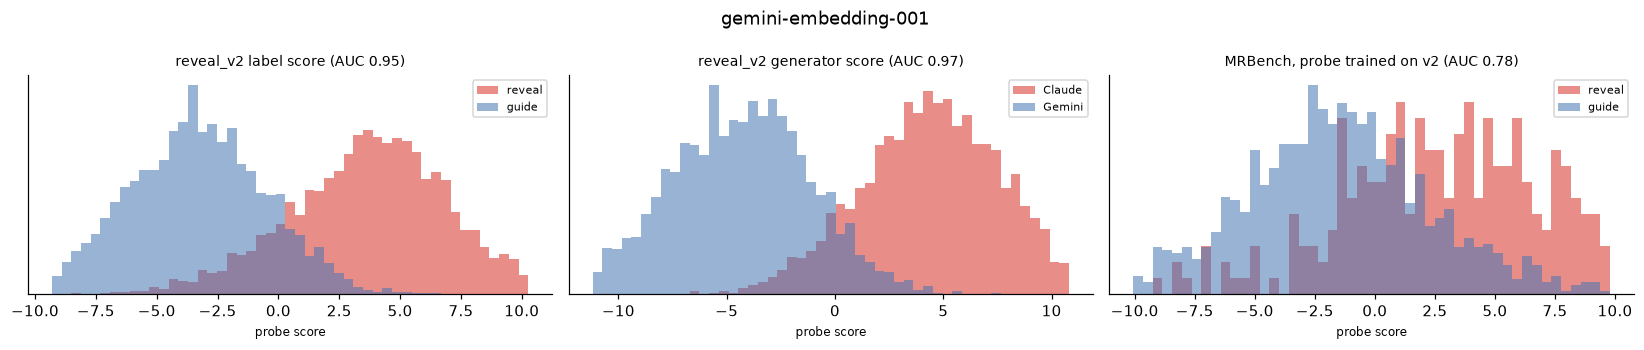

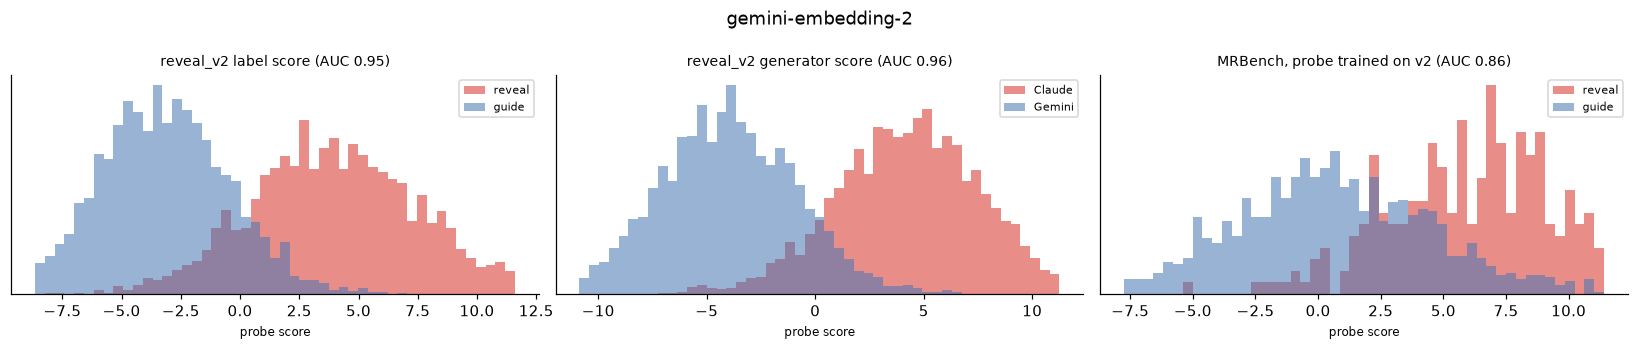

In [8]:
from sklearn.model_selection import GroupKFold


def oof_scores(X, y, groups, folds=5):
    """Out-of-fold probe scores, same probe and grouping as ea.probe_cv."""
    s = np.zeros(len(y))
    for tr, te in GroupKFold(folds).split(X, y, groups):
        s[te] = ea.fit_probe(X[tr], y[tr]).decision_function(X[te])
    return s


v2, mrb = ea.load(ea.V2), ea.load(ea.MRB)
lab = np.array([r["label"] == "yes" for r in v2])
gen = np.array([r["generator"] for r in v2])
grp = np.array([r["problem_id"] for r in v2])
split = np.array([r["split"] for r in v2])
ym = np.array([r["label"] == "yes" for r in mrb])
two = np.isin(gen, ["claude-haiku-5-5", "gemini"])


def hist2(ax, s, mask, names, title):
    bins = np.linspace(*np.percentile(s, [1, 99]), 50)
    for k, name, c in ((mask, names[0], "#d73027"), (~mask, names[1], "#4575b4")):
        ax.hist(s[k], bins, alpha=0.55, color=c, label=name, density=True)
    ax.set_title(title, fontsize=9)
    ax.set_yticks([])
    ax.legend(fontsize=7)


for m in MODELS:
    E, _ = ea.embed_texts(m, [r["response"] for r in v2 + mrb])  # cache hit only
    X2, XM = E[:len(v2)], E[len(v2):]
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.2))
    hist2(axs[0], oof_scores(X2, lab, grp), lab, ["reveal", "guide"], f"reveal_v2 label score (AUC {R[m]['probe_cv']['label']:.2f})")
    isc = gen[two] == "claude-haiku-5-5"
    hist2(axs[1], oof_scores(X2[two], isc, grp[two]), isc, ["Claude", "Gemini"], f"reveal_v2 generator score (AUC {R[m]['probe_cv']['generator']:.2f})")
    p = ea.fit_probe(X2[split == "train"], lab[split == "train"])
    hist2(axs[2], p.decision_function(XM), ym, ["reveal", "guide"], f"MRBench, probe trained on v2 (AUC {R[m]['transfer']['v2_mrbench']:.2f})")
    for a in axs:
        a.set_xlabel("probe score", fontsize=8)
    fig.suptitle(m)
    fig.tight_layout()
    plt.show()

**Reading.** Inside reveal_v2 the reveal and guide histograms sit clearly apart, and so do Claude and Gemini: the
embedding does separate both, just not along the axes t-SNE picks. On MRBench the two humps overlap much more, which is
the transfer drop from section 3 made visible.

## 7. New: held-out generator test

Does the label probe still work when the test replies come from a model it never saw? Train on one generator's train split,
test on the other generator's val split (problem-disjoint), and compare with testing on the same generator. A large drop means
the probe partly learned the writer's style. Uses the cached vectors in `runs/embed/`, so it costs nothing and needs no API key.
`gpt-oss-120b` has only 326 rows, so it is only used as an extra test set.

In [9]:
v2, mrb = ea.load(ea.V2), ea.load(ea.MRB)
ym = np.array([r["label"] == "yes" for r in mrb])
lab = np.array([r["label"] == "yes" for r in v2])
gen = np.array([r["generator"] for r in v2])
split = np.array([r["split"] for r in v2])
GENS = ["claude-haiku-5-5", "gemini", "gpt-oss-120b"]

rows = []
for m in MODELS:
    E, _ = ea.embed_texts(m, [r["response"] for r in v2 + mrb])  # cache hit only, no API call
    X2, XM = E[:len(v2)], E[len(v2):]
    for tr in GENS[:2]:
        k = (gen == tr) & (split == "train")
        probe = ea.fit_probe(X2[k], lab[k])
        row = {"embedder": m, "train on": tr}
        for te in GENS:
            t = (gen == te) & (split == "val")
            row[f"val {te}"] = ea.transfer_auc(probe, X2[t], lab[t])
        row["MRBench"] = ea.transfer_auc(probe, XM, ym)
        rows.append(row)
held = pd.DataFrame(rows).set_index(["embedder", "train on"]).round(3)
held

val claude-haiku-5-5  val gemini  \
embedder             train on                                             
minilm               claude-haiku-5-5                 0.883       0.796   
                     gemini                           0.821       0.866   
bge-small            claude-haiku-5-5                 0.900       0.844   
                     gemini                           0.865       0.876   
gemini-embedding-001 claude-haiku-5-5                 0.952       0.910   
                     gemini                           0.924       0.941   
gemini-embedding-2   claude-haiku-5-5                 0.937       0.917   
                     gemini                           0.902       0.932   

                                       val gpt-oss-120b  MRBench  
embedder             train on                                     
minilm               claude-haiku-5-5             0.907    0.679  
                     gemini                       0.902    0.700  
bge-small            claude-haiku-5-5             0.873    0.748  
                     gemini                       0.868    0.786  
gemini-embedding-001 claude-haiku-5-5             0.970    0.827  
                     gemini                       0.974    0.765  
gemini-embedding-2   claude-haiku-5-5             0.917    0.827  
                     gemini                       0.961    0.843

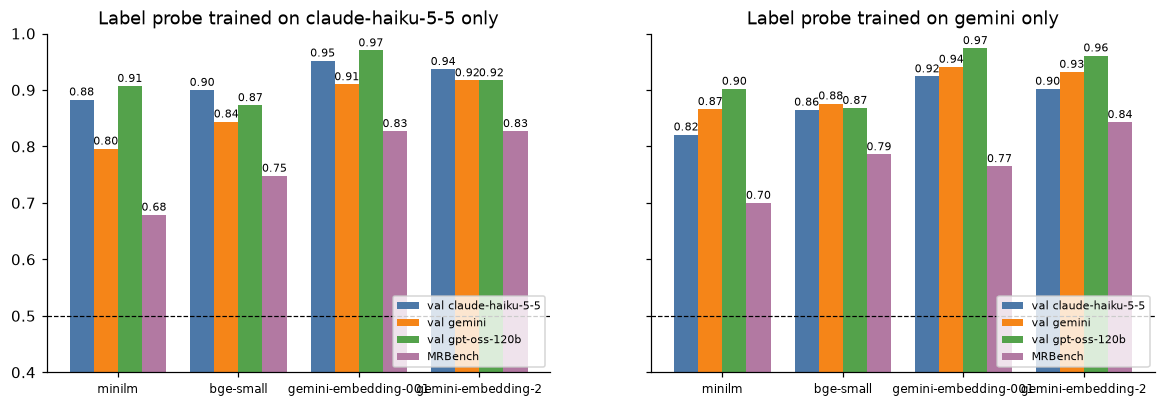

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, tr in zip(axs, GENS[:2]):
    sub = held.xs(tr, level="train on")
    bars(ax, MODELS, {c: sub.loc[MODELS, c].tolist() for c in sub.columns}, f"Label probe trained on {tr} only")
plt.show()

**Reading.** Swapping the writer costs a few points, not a collapse: 2-3 points for the Gemini embedders
(for example gemini-embedding-2, trained on Gemini: 0.932 on Gemini val, 0.902 on Claude val), up to 9 points for MiniLM.
An unseen third family (gpt-oss-120b) still scores 0.87-0.97. So the style signal from section 2 is real but only part of
what the probe uses. The bigger loss is the move to MRBench (0.68-0.84 with one generator, about 2-3 points below training on
both), which points to the domain gap in section 4 as the main problem, more than any single writer's style.

## 8. Re-run

Everything above reads saved results, so the notebook runs in seconds. To recompute the metrics and plots, set `RERUN = True`.
Vectors are cached in `runs/embed/` (git-ignored), so a rerun only calls the Gemini API for texts not seen before
(about $0.15-0.35 for a full re-embed, needs `GEMINI_API_KEY`). Local models need no key.

Setup: `uv sync --extra embed`, then pick the project's `.venv` as the kernel.

In [11]:
RERUN = False
if RERUN:
    for m in MODELS:
        ea.audit(m)
    R = {m: json.load(open(OUT / f"{m}.json")) for m in MODELS}

## Limits

- Reply-only embeddings; conversation plus reply was not tried.
- One probe setting (C=0.05) everywhere, one seed, no confidence intervals. MRBench Bridge has 495 rows with few positives,
  so differences of a few points on slices are noise.
- Gemini vectors cut to 768 dims.